# EDA Provincial — Demanda Electrica por Provincia

Este notebook complementa al EDA nacional (`notebooks/eda.ipynb`, guiado por `eda_organizacion.md`). Todo lo que ya se analizo alli (calidad general del dataset nacional, demanda diaria, forma vs nivel, calendario, clima, outliers y eventos sociales) aplica tambien aca y no se repite.

La diferencia central es que ahora la unidad de analisis es el sistema completo de 22 provincias:

```text
fecha | buenos_aires_01 | buenos_aires_02 | ... | tucuman_24
```

Esto habilita dos analisis nuevos que no eran posibles con el dato nacional agregado, y que son el contenido de este notebook:

1. **Calidad del dataset provincial**: confirmar que las 22 series estan completas y son consistentes entre si y con el total nacional.
2. **Distribucion espacial de la demanda**: entender como se reparte el consumo entre provincias y si esa distribucion es estable en el tiempo.

Estos resultados informan directamente las decisiones de modelado: si tiene sentido modelar el sistema completo de forma conjunta (como hace el CVAE del proyecto) y que provincias van a ser mas dificiles de reproducir.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from pathlib import Path
import os
import sys


def find_repo_root(start: Path) -> Path:
    """Walk upwards from start until the folder with provincias/ and src/ is found."""
    current = start
    for _ in range(5):
        if (current / "provincias").exists() and (current / "src").exists():
            return current
        current = current.parent
    raise FileNotFoundError("No se encontro la raiz del repositorio")


project_root = find_repo_root(Path.cwd())
sys.path.append(str(project_root))

os.environ.setdefault("MPLCONFIGDIR", "/tmp/matplotlib-cache")
Path(os.environ["MPLCONFIGDIR"]).mkdir(parents=True, exist_ok=True)

from provincias.src.provincial_data_quality import (
    build_provincial_quality_summary,
    load_provincial_datasets,
    load_national_hourly_demand,
)
from provincias.src.provincial_spatial_distribution import (
    compute_participation_by_hour,
    compute_participation_by_month,
    compute_participation_by_season,
    compute_province_participation,
    plot_participation_barplot,
    plot_participation_heatmap_by_hour,
    plot_participation_heatmap_by_month,
    plot_typical_day_stacked_area,
    summarize_top_province_concentration,
)

## 1. Calidad del Dataset Provincial

Ademas de los chequeos generales del EDA nacional, aca verificamos lo especifico de tener 22 series simultaneas: que las 22 provincias esten presentes todos los dias, que no haya provincias con nulos o ceros sistematicos, y que la suma provincial coincida tanto con la columna `TOTAL` de los archivos crudos como con la serie nacional que ya se habia construido para el EDA general.

In [3]:
quality_summary = build_provincial_quality_summary(project_root)
quality_summary["date_coverage"]

{'start_date': datetime.date(2019, 1, 1),
 'end_date': datetime.date(2026, 4, 30),
 'observed_days': 2311,
 'expected_days': 2311,
 'missing_days': 0,
 'years_present': [2019, 2021, 2022, 2023, 2024, 2025, 2026]}

El dataset provincial cubre del 2019-01-01 al 2026-04-30, con 2.311 dias observados sobre 2.311 dias esperados (excluyendo 2020 por la anomalia de pandemia, tal como en el dataset nacional). No hay dias faltantes: la cobertura temporal esta completa para los 22 anios-provincia simultaneamente.

In [4]:
quality_summary["hours_per_day_counts"]

hora
24    2311
Name: count, dtype: int64

In [5]:
quality_summary["duplicate_hourly_records"]

0

Los 2.311 dias tienen exactamente 24 registros horarios cada uno, y no hay registros fecha-hora duplicados. Esto confirma que la base horaria provincial (`dataset_base_horario.csv`, 55.464 filas = 2.311 dias x 24 horas) esta completa para las 22 provincias a la vez.

In [6]:
quality_summary["missing_by_province"]

,provincia,valores_faltantes,dias_afectados,primera_fecha_afectada,ultima_fecha_afectada
0,catamarca,1,1,2023-12-17,2023-12-17
1,jujuy,1,1,2023-12-17,2023-12-17
2,san_luis,1,1,2023-03-01,2023-03-01


Solo 3 valores nulos en todo el dataset, concentrados en 2 fechas puntuales (2023-03-01 para San Luis, 2023-12-17 para Catamarca y Jujuy). Son huecos aislados de una sola hora en provincias chicas, no un problema sistematico de ninguna serie. No ameritan imputacion especial: alcanza con dejarlos como NaN o excluir esas filas puntuales si un modelo lo requiere.

In [7]:
quality_summary["zero_values_by_province"]

,provincia,valores_cero,valores_negativos,primera_fecha_cero,ultima_fecha_cero
0,jujuy,1,0,2019-06-16,2019-06-16
1,la_pampa,10,0,2019-06-16,2019-06-16
2,la_rioja,6,0,2019-06-16,2019-06-16
3,san_luis,7,0,2019-06-16,2019-06-16
4,santa_cruz,6,0,2019-06-16,2019-06-16
5,tucuman,5,0,2019-06-16,2019-06-16


Los valores en cero tambien son puntuales, pero a diferencia de los nulos, todos caen exactamente el mismo dia: 2019-06-16, y afectan a las provincias mas chicas del sistema (La Pampa, Tucuman, San Luis, Santa Cruz, La Rioja y Jujuy). Que varias provincias reporten demanda cero el mismo dia sugiere un corte puntual de medicion o carga en la fuente original ese dia, mas que un apagon real simultaneo en seis provincias distintas. Es un candidato a dia atipico a revisar en la seccion de outliers del EDA completo, no un error a corregir aca.

In [8]:
quality_summary["raw_total_consistency"]

,fuente,registros,provincias_encontradas,diferencia_absoluta_media_mwh,diferencia_absoluta_maxima_mwh,registros_con_diferencia_mayor_a_1_mwh
0,2019_2022,35064,22,0.106223,0.6,0
1,2023_2026,29184,22,0.250709,0.5,0


Comparando la suma de las 22 provincias contra la columna `TOTAL` de cada archivo crudo original, la diferencia absoluta media es de apenas 0,11-0,25 MWh, con un maximo de 0,6 MWh en mas de 64.000 registros. Estas diferencias son consistentes con redondeo de datos y no representan un problema real: la columna `TOTAL` de CAMMESA y la suma de provincias describen la misma cantidad.

In [9]:
quality_summary["provincial_sum_vs_national_series"]

,registros_comparados,diferencia_absoluta_media_mwh,diferencia_absoluta_maxima_mwh,diferencia_pct_media,diferencia_pct_maxima,registros_con_diferencia_mayor_a_1pct
0,46704,0.471292,32.442,0.003025,0.138426,0


La comparacion contra la serie nacional (`dataset_base_horario.csv` de la raiz del proyecto, construida de forma independiente a partir de otro archivo fuente) tambien confirma consistencia: sobre 46.704 registros horarios en el periodo 2021-2026, la diferencia porcentual promedio es de 0,003% y la maxima es de 0,14% (equivalente a unos 32 MWh en una hora de diciembre de 2022, sobre una demanda de mas de 20.000 MWh). Ninguna hora supera el 1% de diferencia. Esto valida que el dataset provincial y el nacional describen el mismo sistema electrico real, construidos desde fuentes distintas.

**Conclusion de la seccion 1**: el dataset provincial esta completo (22 provincias, todos los dias, sin huecos estructurales), es internamente consistente (la suma de provincias coincide con el TOTAL crudo y con la serie nacional) y solo tiene anomalias puntuales y menores (3 nulos aislados, un dia con ceros simultaneos en provincias chicas). Esta en condiciones de usarse para modelar.

## 2. Distribucion Espacial de la Demanda

Este es el analisis nuevo respecto al EDA nacional: como se reparte el consumo electrico entre las 22 provincias, y si esa distribucion espacial es estable o cambia segun la hora del dia y la epoca del anio. Para esto trabajamos con el share de cada provincia sobre la demanda nacional en cada registro horario:

```text
share_provincia_hora = demanda_provincia_hora / demanda_total_hora
```

In [10]:
hourly_demand = load_provincial_datasets(project_root)["dataset_base_horario"]
participation = compute_province_participation(hourly_demand)
participation

,provincia,participacion_pct
0,buenos_aires,49.132397
1,santa_fe,9.245988
2,cordoba,7.550660
3,mendoza,4.357732
4,chubut,3.515503
5,entre_rios,2.808002
6,tucuman,2.375930
7,chaco,2.301535
8,corrientes,2.189433
9,misiones,1.922194


Buenos Aires concentra en promedio el 49,1% de la demanda electrica nacional, muy por encima de Santa Fe (9,2%) y Cordoba (7,6%), que son las siguientes en el ranking. Entre las tres provincias mas grandes concentran cerca de dos tercios del sistema (se calcula exactamente a continuacion). En el otro extremo, La Pampa, Jujuy y Santa Cruz participan con menos del 1% cada una: son provincias chicas cuyo aporte al sistema conjunto es marginal en terminos de nivel, aunque no necesariamente en terminos de variabilidad relativa.

In [11]:
top3_concentration = summarize_top_province_concentration(participation)
top3_concentration

65.92904546280782

Buenos Aires, Cordoba y Santa Fe concentran en conjunto casi el 66% de la demanda electrica nacional. Esto tiene una implicancia directa para el modelo generativo: el vector `x` de 528 dimensiones esta dominado en magnitud por un puñado de provincias, por lo que conviene evaluar el modelo por provincia (como plantea la seccion de evaluacion del proyecto) en lugar de mirar solo el error agregado, que va a estar naturalmente dominado por Buenos Aires.

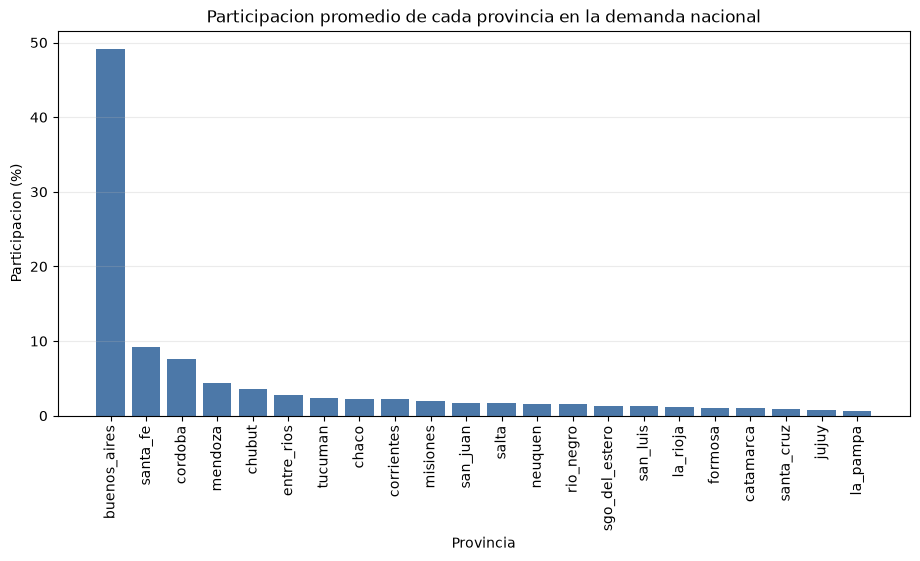

In [12]:
plot_participation_barplot(participation);

El grafico de barras confirma la fuerte heterogeneidad de tamaño entre provincias: la caida de participacion desde Buenos Aires hacia el resto del sistema es abrupta, y la mayoria de las provincias del interior participan con valores de un digito o menos. Esto es consistente con la geografia economica y demografica real de Argentina.

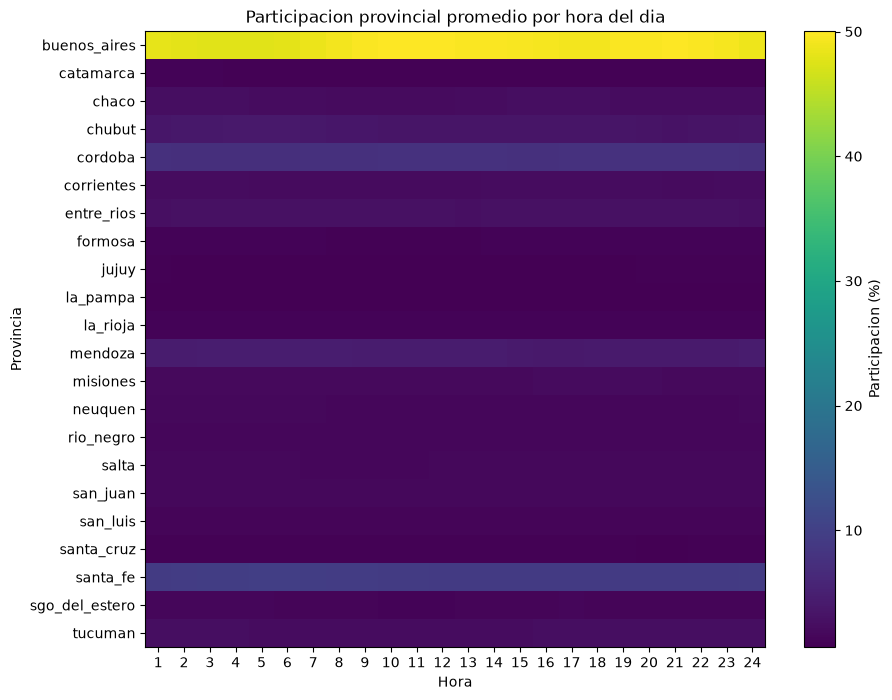

In [13]:
participation_by_hour = compute_participation_by_hour(hourly_demand)
plot_participation_heatmap_by_hour(participation_by_hour);

La participacion de cada provincia varia poco entre horas: para Buenos Aires, por ejemplo, el share horario promedio se mueve entre 47,9% (madrugada, hora 4-5) y 50,0% (media mañana, hora 11), una banda de apenas 2 puntos porcentuales. La distribucion espacial de la demanda es entonces bastante mas estable dentro del dia que el nivel total, que si tiene una forma horaria marcada (valle de madrugada, pico nocturno, segun el EDA nacional). Esto sugiere que la forma horaria del sistema es en gran medida un fenomeno nacional compartido, mas que un desacople entre provincias a lo largo del dia.

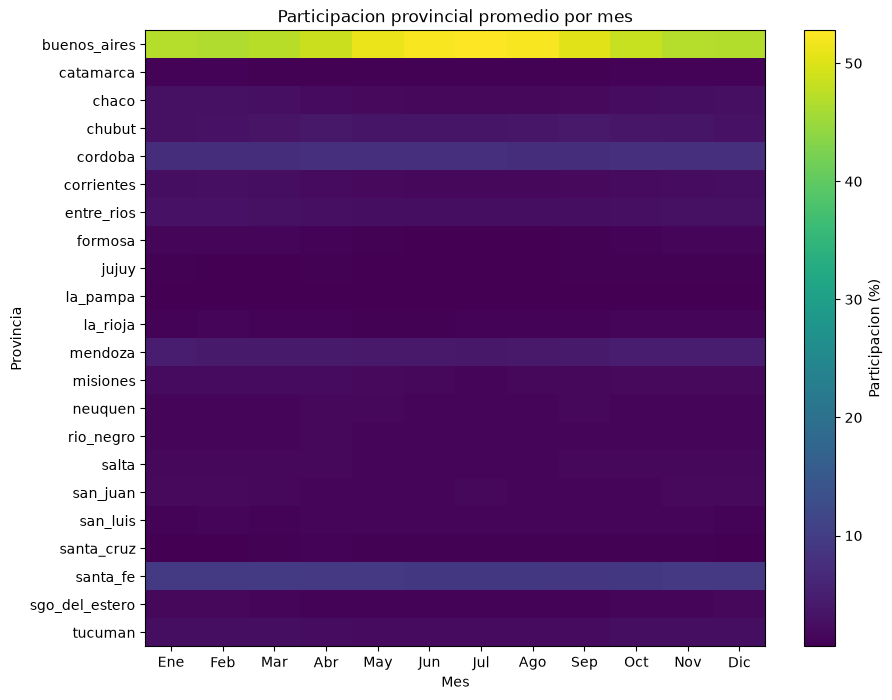

In [14]:
participation_by_month = compute_participation_by_month(hourly_demand)
plot_participation_heatmap_by_month(participation_by_month);

In [15]:
participation_by_season = compute_participation_by_season(hourly_demand)
participation_by_season[["buenos_aires", "cordoba", "santa_fe", "la_rioja", "santa_cruz"]].round(2)

,buenos_aires,cordoba,santa_fe,la_rioja,santa_cruz
estacion,,,,,
Verano,46.83,7.52,9.44,1.25,0.76
Otonio,48.95,7.54,9.35,1.06,0.95
Invierno,52.42,7.54,9.03,1.03,0.90
Primavera,48.54,7.62,9.13,1.23,0.95


A diferencia de la hora del dia, la estacion del anio si mueve la distribucion espacial de forma notoria. La participacion de Buenos Aires sube de 46,8% en verano a 52,4% en invierno, una diferencia de mas de 5 puntos porcentuales, mientras que provincias del norte con clima calido (como La Rioja) y del sur con clima frio (como Santa Cruz) ganan participacion relativa en verano. Una lectura razonable es que el uso de aire acondicionado en verano aumenta mas que proporcionalmente la demanda relativa en provincias del norte de clima calido, mientras que en invierno el peso del area metropolitana de Buenos Aires (con una base de consumo residencial y comercial mucho mayor) se hace mas dominante. Esto valida la necesidad de incluir clima e indicadores por provincia en el vector condicional `c`, en lugar de asumir una distribucion espacial fija.

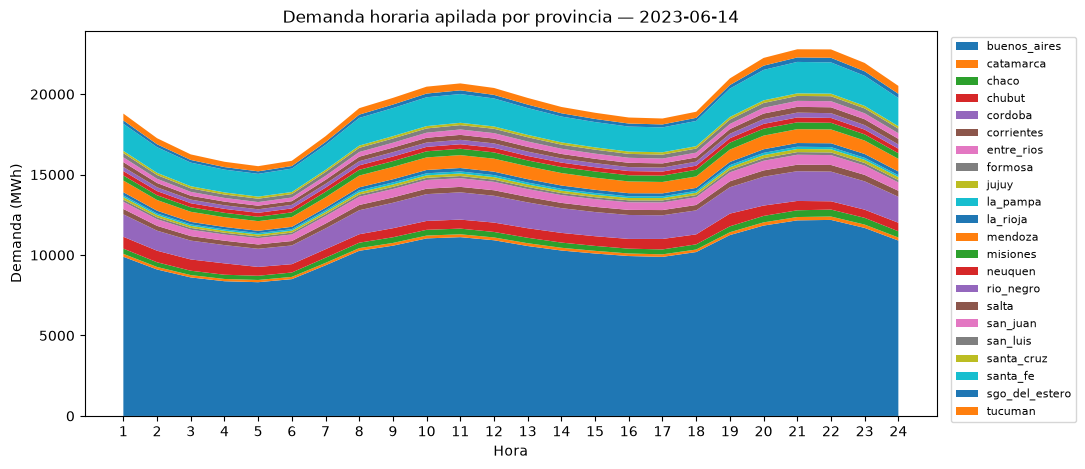

In [16]:
plot_typical_day_stacked_area(hourly_demand, "2023-06-14");

El grafico apilado de un miercoles habil de invierno (14/06/2023, sin feriado) muestra visualmente la composicion del sistema hora a hora: la banda de Buenos Aires domina el grafico en todo momento, y el resto de las provincias se apilan en franjas mucho mas finas y relativamente constantes en espesor a lo largo del dia. Esto es consistente con el hallazgo de la seccion anterior: la forma horaria del sistema completo esta dominada por la forma horaria de Buenos Aires, con contribuciones proporcionalmente estables del resto de las provincias dentro de un mismo dia.

**Conclusion de la seccion 2**: el sistema electrico argentino esta fuertemente concentrado en pocas provincias (Buenos Aires, Cordoba y Santa Fe explican cerca del 66% de la demanda), y esa concentracion es muy estable dentro del dia pero cambia de forma marcada entre estaciones, con un corrimiento hacia Buenos Aires en invierno y hacia provincias de clima calido en verano. Esto confirma que modelar el sistema conjunto (en lugar de provincias independientes) tiene sentido porque hay estructura espacial compartida, pero tambien que el modelo va a necesitar clima e indicadores socioeconomicos por provincia para capturar estos corrimientos estacionales en la distribucion del consumo, no solo el nivel nacional total.

Nota: no se incluye un mapa de Argentina coloreado por consumo porque el repositorio no cuenta con un archivo geografico (shapefile o GeoJSON) de las provincias; el ranking de participacion y los heatmaps provincia x hora / provincia x mes cubren el mismo objetivo de forma tabular.